# ¿Esta respuesta del RAG está respaldada por sus fuentes?

**Detección de alucinaciones en respuestas de sistemas RAG con aprendizaje supervisado**

Proyecto final · MMIA 6012 Aprendizaje Supervisado · USFQ
Autor: Marco David Escobar Aleaga · Noviembre 2026

## 1. Introducción

Un sistema RAG (*Retrieval-Augmented Generation*) [1] primero busca pasajes en una base de documentos y después le pide a un LLM que responda usando solo esos pasajes. La idea es que el modelo no invente. Aun así, el LLM a veces agrega datos que no están en los pasajes o los contradice. A eso se le llama **alucinación**.

Esto importa porque quien usa un RAG confía en que la respuesta sale de los documentos. Si el sistema se usa, por ejemplo, para consultar vulnerabilidades de seguridad o normativa, una respuesta inventada puede llevar a una mala decisión.

**Problema que resuelvo:** dada una pregunta, los pasajes recuperados y la respuesta del LLM, predecir si la respuesta es **fiel** a los pasajes (clase 0) o si **contiene una alucinación** (clase 1). Es una clasificación binaria supervisada.

Este proyecto es el primer paso de mi tema de titulación (verificación factual en sistemas RAG): el clasificador que construyo aquí es el módulo "verificador" que después quiero poner al final de un RAG.

**Qué hago en esta notebook:**
1. Exploro el dataset RAGTruth [2].
2. Extraigo features con modelos preentrenados (transfer learning).
3. Armo dos pipelines (regresión logística y XGBoost) con selección de features tipo filter.
4. Optimizo sus hiperparámetros con Optuna y repeated k-fold.
5. Comparo los dos modelos con un test de Wilcoxon.
6. Visualizo el espacio de features con t-SNE.
7. Evalúo el modelo final una sola vez en el conjunto de test.

## 2. Configuración

In [1]:
# Desarrollé este proyecto con apoyo de Claude (Anthropic). Prompts principales:
# "Quisiera que revises qué debemos hacer del proyecto [...] y cómo lo haríamos."
# "Necesito que lo implementes y también que me enseñes lo que estamos haciendo para yo poder exponerlo."
import os, sys
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

if "google.colab" in sys.modules:
    if not os.path.exists("verificador-rag"):
        !git clone -q https://github.com/dabarlea/verificador-rag.git
    %cd verificador-rag
    !pip install -q optuna sentence-transformers

In [2]:
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from scipy.special import softmax
from scipy.stats import wilcoxon
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (StratifiedGroupKFold, cross_val_predict, cross_val_score,
                                     learning_curve, validation_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.rcParams["figure.dpi"] = 110

SEMILLA = 42

## 3. Datos: RAGTruth

RAGTruth [2] es un corpus público (licencia MIT) hecho para estudiar alucinaciones en RAG. Tiene respuestas reales de 6 LLM (GPT-3.5, GPT-4, Llama-2 de 7B, 13B y 70B, y Mistral-7B). Personas revisaron cada respuesta y marcaron los tramos de texto que no están respaldados por los pasajes.

El corpus tiene tres tareas (preguntas y respuestas, resumen y datos a texto). Uso solo **preguntas y respuestas (QA)**, que es el caso de un RAG: cada pregunta viene de MS MARCO [3] con 3 pasajes recuperados, y hay 6 respuestas por pregunta (una por LLM).

**Etiqueta:** `y = 1` si la respuesta tiene al menos un tramo marcado como alucinación, `y = 0` si no tiene ninguno. Es la misma definición "a nivel de respuesta" que usa el paper.

In [3]:
if not os.path.exists("data/RAGTruth"):
    !git clone -q --depth 1 https://github.com/ParticleMedia/RAGTruth.git data/RAGTruth

respuestas = pd.read_json("data/RAGTruth/dataset/response.jsonl", lines=True, dtype={"id": str, "source_id": str})
fuentes = pd.read_json("data/RAGTruth/dataset/source_info.jsonl", lines=True, dtype={"source_id": str})
fuentes = fuentes[fuentes["task_type"] == "QA"]
fuentes["pregunta"] = fuentes["source_info"].map(lambda d: d["question"])
fuentes["pasajes"] = fuentes["source_info"].map(
    lambda d: [re.sub(r"^passage \d+:", "", p).strip() for p in d["passages"].split("\n\n") if p.strip()])

df = respuestas.merge(fuentes[["source_id", "pregunta", "pasajes"]], on="source_id")
df["y"] = df["labels"].map(lambda tramos: int(len(tramos) > 0))
df = df.rename(columns={"response": "respuesta", "model": "llm"}).reset_index(drop=True)

print("Respuestas:", len(df), "| Preguntas:", df["source_id"].nunique())
df[["id", "source_id", "llm", "split", "pregunta", "respuesta", "y"]].head(3)

Respuestas: 5934 | Preguntas: 989


,id,source_id,llm,split,pregunta,respuesta,y
0,11856,14292,gpt-4-0613,train,butcher shop phone number,The phone numbers for several butcher shops ar...,0
1,11857,14292,gpt-3.5-turbo-0613,train,butcher shop phone number,Butcher Shop - Hayward phone number: (510) 889...,0
2,11858,14292,mistral-7B-instruct,train,butcher shop phone number,"Based on the given passages, there are several...",1


## 4. Análisis exploratorio (EDA)

In [4]:
resumen = df.groupby("split").agg(respuestas=("y", "size"), preguntas=("source_id", "nunique"),
                                  tasa_alucinacion=("y", "mean")).round(3)
print(resumen)
print("\nRespuestas por pregunta:", df.groupby("source_id").size().unique())
print("Pasajes por pregunta:", df["pasajes"].map(len).unique())
compartidas = set(df[df.split == "train"].source_id) & set(df[df.split == "test"].source_id)
print("Preguntas que están en train y en test a la vez:", len(compartidas))

       respuestas  preguntas  tasa_alucinacion
split                                         
test          900        150             0.178
train        5034        839             0.311

Respuestas por pregunta: [6]
Pasajes por pregunta: [3]
Preguntas que están en train y en test a la vez: 0


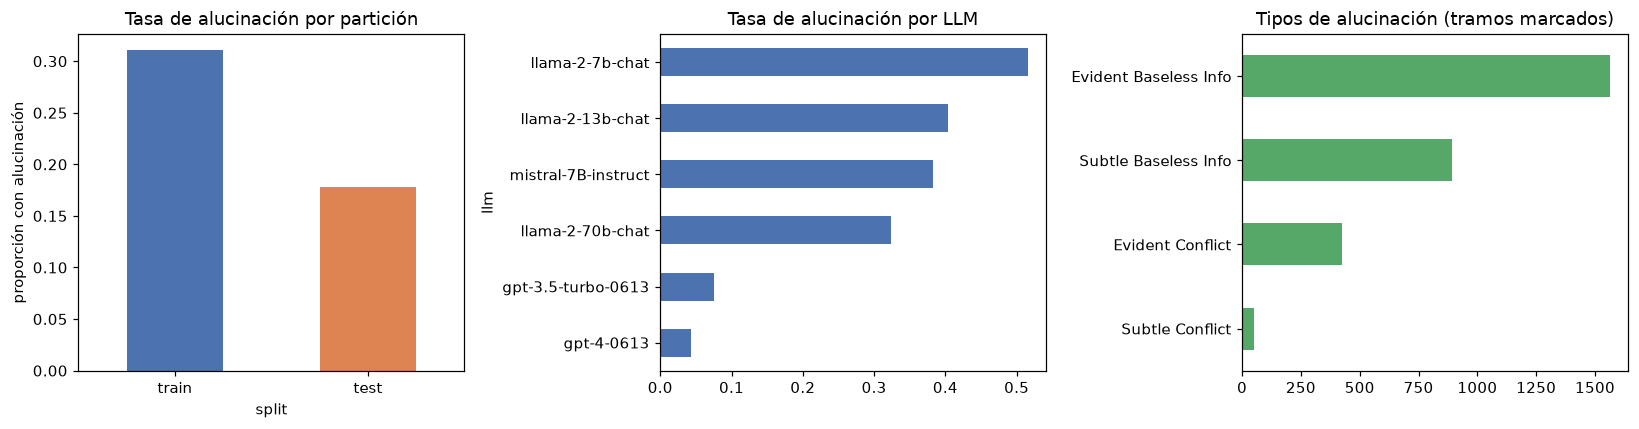

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df.groupby("split")["y"].mean().loc[["train", "test"]].plot.bar(ax=ax[0], color=["#4C72B0", "#DD8452"], rot=0)
ax[0].set_title("Tasa de alucinación por partición")
ax[0].set_ylabel("proporción con alucinación")

df.groupby("llm")["y"].mean().sort_values().plot.barh(ax=ax[1], color="#4C72B0")
ax[1].set_title("Tasa de alucinación por LLM")

tipos = pd.Series([t["label_type"] for tramos in df["labels"] for t in tramos]).value_counts()
tipos.sort_values().plot.barh(ax=ax[2], color="#55A868")
ax[2].set_title("Tipos de alucinación (tramos marcados)")
plt.tight_layout()
plt.show()

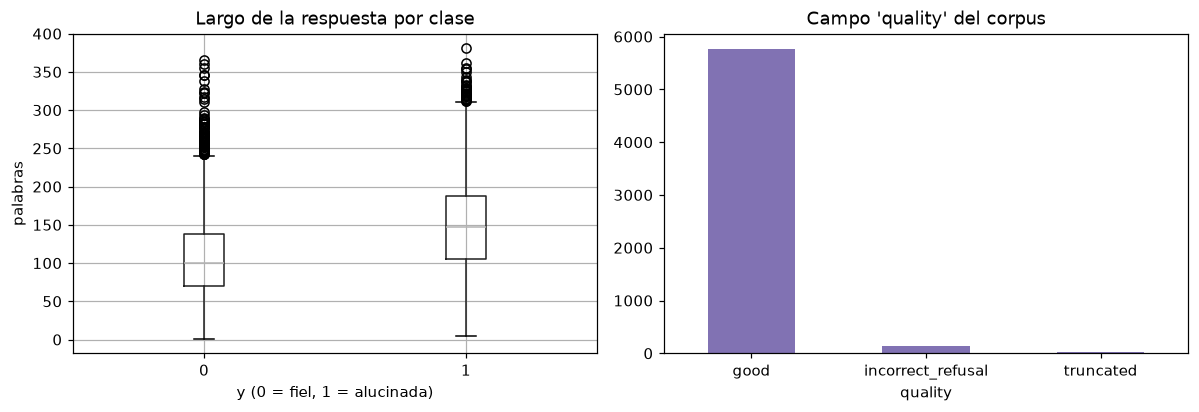

    count   mean   std  min    25%    50%    75%    max
y                                                      
0  4210.0  105.5  55.7  1.0   70.0  100.0  138.0  366.0
1  1724.0  151.5  63.7  5.0  104.8  147.0  187.2  381.0


In [6]:
df["n_palabras"] = df["respuesta"].str.split().map(len)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.boxplot(column="n_palabras", by="y", ax=ax[0])
ax[0].set_title("Largo de la respuesta por clase")
ax[0].set_xlabel("y (0 = fiel, 1 = alucinada)")
ax[0].set_ylabel("palabras")
df["quality"].value_counts().plot.bar(ax=ax[1], rot=0, color="#8172B3")
ax[1].set_title("Campo 'quality' del corpus")
plt.suptitle("")
plt.tight_layout()
plt.show()

print(df.groupby("y")["n_palabras"].describe().round(1))

In [7]:
ejemplo = df[(df.y == 1) & (df.n_palabras < 60)].iloc[0]
print("PREGUNTA:", ejemplo["pregunta"])
print("\nPASAJE 1:", ejemplo["pasajes"][0][:400], "...")
print("\nRESPUESTA (" + ejemplo["llm"] + "):", ejemplo["respuesta"])
print("\nTRAMOS MARCADOS:")
for t in ejemplo["labels"]:
    print(" -", t["label_type"], "->", repr(t["text"]))

PREGUNTA: butcher shop phone number

PASAJE 1: Butcher Shop - Hayward 826 B Street, Hayward CA 94541 Phone Number: (510) 889-8690 ...

RESPUESTA (mistral-7B-instruct): Based on the given passages, there are several different phone numbers associated with butcher shops. However, none of them are for a specific location named "bear" or have any indication of being related to bears. Therefore, it is unable to determine if there is a butcher shop phone number specifically for "bear".

TRAMOS MARCADOS:
 - Evident Baseless Info -> 'However, none of them are for a specific location named "bear" or have any indication of being related to bears.'


**Lo que veo en el EDA**

- Son 5 934 respuestas de 989 preguntas. Cada pregunta tiene 6 respuestas (una por LLM) y 3 pasajes.
- **Las clases están desbalanceadas:** en train el 31,1 % de las respuestas tiene alguna alucinación y en test el 17,8 %. El test es un escenario distinto al train, y lo tengo en cuenta al final.
- **El LLM influye mucho:** GPT-4 alucina en el 4,2 % de sus respuestas y GPT-3.5 en el 7,6 %, mientras que Llama-2-7B lo hace en el 51,6 %.
- **La mayoría de alucinaciones son información inventada, no contradicciones:** de 2 927 tramos marcados, 2 455 (84 %) son "Baseless Info" y solo 472 son "Conflict".
- **Las respuestas alucinadas son más largas:** 151 palabras en promedio contra 105 de las fieles.
- Hay 143 respuestas marcadas como `incorrect_refusal` y 24 como `truncated`. Las dejo, porque un RAG real también produce ese tipo de respuestas.
- Ninguna pregunta aparece a la vez en train y en test.

## 5. Extracción de features con transfer learning

El texto no entra directo a los modelos, así que lo convierto en números usando dos modelos **preentrenados y congelados** (no los reentreno, solo los uso para extraer features):

1. **Embeddings** con `all-MiniLM-L6-v2` [4], [5]: convierte un texto en un vector de 384 números. Textos con significado parecido quedan con vectores parecidos, y eso lo mido con la similitud coseno.
2. **NLI** (*Natural Language Inference*) con `nli-deberta-v3-small` [6]: recibe dos oraciones, una de la fuente y una de la respuesta, y devuelve la probabilidad de que la primera **respalde** a la segunda (*entailment*), la **contradiga** (*contradiction*) o ninguna de las dos (*neutral*).

El procedimiento sigue la idea de SummaC [7], que trabaja oración por oración:

1. Parto la respuesta y los pasajes en oraciones.
2. Para cada oración de la respuesta busco, con los embeddings, las **3 oraciones más parecidas** de los pasajes.
3. Le pregunto al modelo NLI si alguna de esas 3 la respalda o la contradice, y me quedo con el mejor respaldo y la mayor contradicción.
4. Resumo todas las oraciones de la respuesta en unas pocas features.

Con eso armo dos grupos de features por respuesta:

- **Features de respaldo (21):**
  - **NLI (8):** respaldo mínimo, promedio y percentil 25 de las oraciones; cuántas oraciones y qué fracción tienen respaldo menor a 0,5; contradicción máxima y promedio; cuántas oraciones tienen contradicción mayor a 0,5.
  - **Similitud (7):** similitud coseno de la respuesta con la pregunta y con los pasajes, y la similitud de cada oración con su oración más parecida de los pasajes (mínimo, promedio y desviación).
  - **Simples (6):** largo, número de oraciones, palabras y números de la respuesta que no aparecen en los pasajes, y si la respuesta es un rechazo ("unable to answer").
- **Embedding de la respuesta (384):** el vector completo de la respuesta.

**Qué entra al modelo:** solo las 21 features de respaldo. El embedding lo extraigo para comparar (sección 7 y t-SNE), pero no lo uso como entrada: describe de qué habla la respuesta, no si está respaldada, y hacer selección de features sobre las dimensiones de un embedding no tiene sentido porque cada dimensión no significa nada por sí sola.

No uso como feature qué LLM generó la respuesta ni su temperatura. En el EDA se ve que predicen mucho, pero un verificador real no siempre sabe qué modelo escribió la respuesta.

Como este paso tarda, guardo el resultado en `data/features.parquet` y, si el archivo ya existe, solo lo leo.

In [8]:
def partir_oraciones(texto):
    partes = re.split(r"(?<=[.!?])\s+|\n+", texto.strip())
    oraciones = [p.strip() for p in partes if len(p.split()) >= 4]
    return oraciones or [texto.strip()]


def palabras(texto):
    return re.findall(r"[a-z]{4,}", texto.lower())


def numeros(texto):
    return re.findall(r"\d+(?:[.,]\d+)*", texto)


def features_simples(fila):
    fuente = " ".join(fila["pasajes"]) + " " + fila["pregunta"]
    vocab_fuente = set(palabras(fuente))
    pals = palabras(fila["respuesta"])
    nums = numeros(fila["respuesta"])
    nums_fuente = set(numeros(fuente))
    return {
        "n_palabras": len(fila["respuesta"].split()),
        "n_oraciones": len(partir_oraciones(fila["respuesta"])),
        "frac_palabras_nuevas": np.mean([p not in vocab_fuente for p in pals]) if pals else 0.0,
        "n_numeros_nuevos": sum(n not in nums_fuente for n in nums),
        "frac_numeros_nuevos": np.mean([n not in nums_fuente for n in nums]) if nums else 0.0,
        "es_rechazo": int("unable to answer" in fila["respuesta"].lower()),
    }

In [9]:
def extraer_features(df):
    import torch
    from sentence_transformers import CrossEncoder, SentenceTransformer

    if torch.cuda.is_available():
        dispositivo = "cuda"
    elif torch.backends.mps.is_available():
        dispositivo = "mps"
    else:
        dispositivo = "cpu"
    print("Dispositivo:", dispositivo)

    modelo_emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=dispositivo)
    modelo_nli = CrossEncoder("cross-encoder/nli-deberta-v3-small", device=dispositivo)
    etiquetas = {v.lower(): k for k, v in modelo_nli.model.config.id2label.items()}

    def emb(textos):
        return modelo_emb.encode(list(textos), batch_size=128, normalize_embeddings=True, show_progress_bar=True)

    def emb_por_grupo(listas):
        # codifica todas las oraciones juntas y las vuelve a separar por grupo
        todo = emb([o for lista in listas for o in lista])
        cortes = np.cumsum([len(lista) for lista in listas])[:-1]
        return np.split(todo, cortes)

    # Oraciones y embeddings de las fuentes (una vez por pregunta) y de las respuestas
    fuentes = df.drop_duplicates("source_id")
    orac_fuente = dict(zip(fuentes["source_id"], fuentes["pasajes"].map(lambda ps: [o for p in ps for o in partir_oraciones(p)])))
    e_orac_fuente = dict(zip(fuentes["source_id"], emb_por_grupo(list(orac_fuente.values()))))
    e_pasajes = dict(zip(fuentes["source_id"], emb_por_grupo(list(fuentes["pasajes"]))))
    e_pregunta = dict(zip(fuentes["source_id"], emb(fuentes["pregunta"])))

    orac_resp = list(df["respuesta"].map(partir_oraciones))
    e_orac_resp = emb_por_grupo(orac_resp)
    e_resp = emb(df["respuesta"])

    # Para cada oración de la respuesta: similitud con las oraciones de la fuente y las 3 más parecidas
    pares, id_resp, id_orac, f_emb = [], [], [], []
    for i, sid in enumerate(df["source_id"]):
        sims = e_orac_resp[i] @ e_orac_fuente[sid].T
        mejores = np.argsort(-sims, axis=1)[:, :3]
        for j, oracion in enumerate(orac_resp[i]):
            for m in mejores[j]:
                pares.append((orac_fuente[sid][m], oracion))
                id_resp.append(i)
                id_orac.append(j)
        sim_orac = sims.max(axis=1)
        sim_pasajes = e_pasajes[sid] @ e_resp[i]
        f_emb.append({
            "cos_resp_pregunta": float(e_resp[i] @ e_pregunta[sid]),
            "cos_resp_pasajes_max": float(sim_pasajes.max()),
            "cos_resp_pasajes_medio": float(sim_pasajes.mean()),
            "cos_oracion_min": float(sim_orac.min()),
            "cos_oracion_medio": float(sim_orac.mean()),
            "cos_oracion_std": float(sim_orac.std()),
            "cos_pregunta_pasajes": float((e_pasajes[sid] @ e_pregunta[sid]).max()),
        })

    # NLI: ¿alguna de las 3 oraciones de la fuente respalda o contradice a la oración de la respuesta?
    print("Pares (oración de la fuente, oración de la respuesta):", len(pares))
    salida = modelo_nli.predict(pares, batch_size=128, show_progress_bar=True)
    probs = salida if np.allclose(salida.sum(axis=1), 1, atol=1e-3) else softmax(salida, axis=1)

    nli = pd.DataFrame({"resp": id_resp, "orac": id_orac,
                        "respaldo": probs[:, etiquetas["entailment"]],
                        "contradiccion": probs[:, etiquetas["contradiction"]]})
    por_oracion = nli.groupby(["resp", "orac"]).max()
    f_nli = por_oracion.groupby("resp").agg(
        nli_respaldo_min=("respaldo", "min"),
        nli_respaldo_medio=("respaldo", "mean"),
        nli_respaldo_p25=("respaldo", lambda r: r.quantile(0.25)),
        nli_n_sin_respaldo=("respaldo", lambda r: (r < 0.5).sum()),
        nli_frac_sin_respaldo=("respaldo", lambda r: (r < 0.5).mean()),
        nli_contradiccion_max=("contradiccion", "max"),
        nli_contradiccion_media=("contradiccion", "mean"),
        nli_n_contradichas=("contradiccion", lambda c: (c > 0.5).sum()),
    )

    f_simples = pd.DataFrame([features_simples(fila) for _, fila in df.iterrows()])
    embedding = pd.DataFrame(e_resp, columns=[f"e{i:03d}" for i in range(e_resp.shape[1])])
    return pd.concat([df[["id"]], f_nli.reset_index(drop=True), pd.DataFrame(f_emb), f_simples, embedding], axis=1)


if os.path.exists("data/features.parquet"):
    feats = pd.read_parquet("data/features.parquet")
else:
    feats = extraer_features(df)
    feats.to_parquet("data/features.parquet", index=False)

assert (feats["id"] == df["id"]).all()
COLS_EMB = [c for c in feats.columns if re.fullmatch(r"e\d{3}", c)]
COLS_NLI = [c for c in feats.columns if c.startswith("nli_")]
COLS_SIM = [c for c in feats.columns if c.startswith("cos_")]
COLS_SIMPLES = [c for c in feats.columns if c not in COLS_EMB + COLS_NLI + COLS_SIM + ["id"]]
COLS_RESPALDO = COLS_NLI + COLS_SIM + COLS_SIMPLES
COLS = COLS_RESPALDO
print("NLI:", len(COLS_NLI), "| Similitud:", len(COLS_SIM), "| Simples:", len(COLS_SIMPLES),
      "| Embedding:", len(COLS_EMB), "| Entrada del modelo:", len(COLS))
feats[COLS_RESPALDO].describe().T.round(3)

NLI: 8 | Similitud: 7 | Simples: 6 | Embedding: 384 | Entrada del modelo: 21


,count,mean,std,min,25%,50%,75%,max
nli_respaldo_min,5934.0,0.045,0.186,0.000,0.000,0.001,0.002,0.999
nli_respaldo_medio,5934.0,0.370,0.279,0.000,0.122,0.355,0.580,0.999
nli_respaldo_p25,5934.0,0.153,0.301,0.000,0.001,0.003,0.081,0.999
nli_n_sin_respaldo,5934.0,4.046,3.011,0.000,2.000,3.000,6.000,25.000
nli_frac_sin_respaldo,5934.0,0.629,0.293,0.000,0.400,0.667,0.889,1.000
nli_contradiccion_max,5934.0,0.704,0.421,0.000,0.158,0.991,0.999,1.000
nli_contradiccion_media,5934.0,0.290,0.266,0.000,0.043,0.244,0.440,1.000
nli_n_contradichas,5934.0,1.958,2.260,0.000,0.000,1.000,3.000,26.000
cos_resp_pregunta,5934.0,0.766,0.171,-0.168,0.748,0.807,0.849,1.000
cos_resp_pasajes_max,5934.0,0.790,0.179,-0.137,0.764,0.833,0.885,0.993


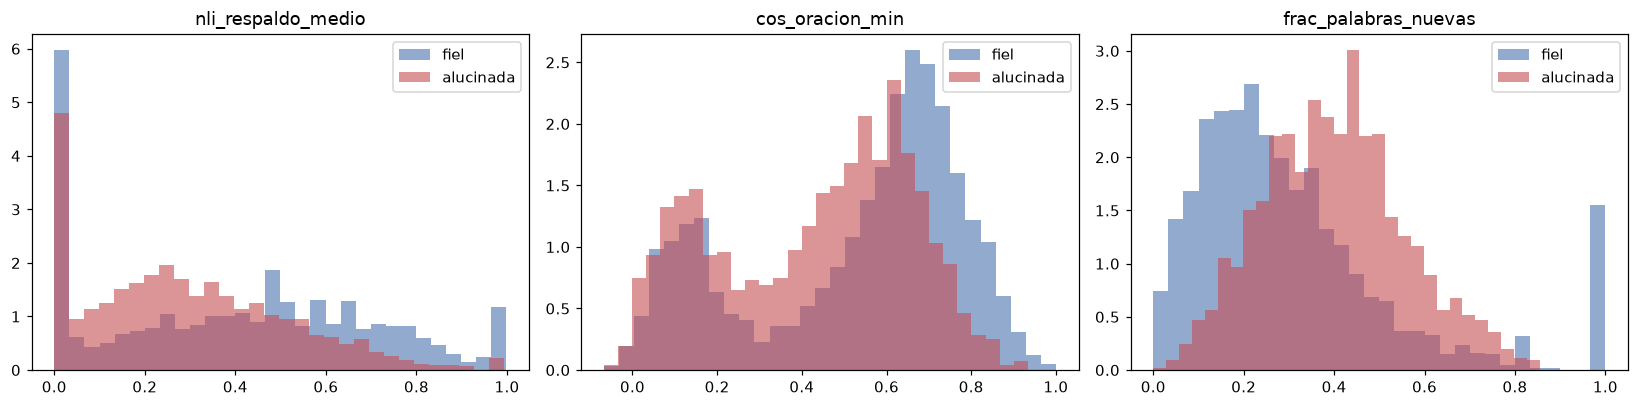

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col in zip(ax, ["nli_respaldo_medio", "cos_oracion_min", "frac_palabras_nuevas"]):
    for clase, color in [(0, "#4C72B0"), (1, "#C44E52")]:
        a.hist(feats.loc[(df.y == clase) & (df.split == "train"), col], bins=30, alpha=0.6, color=color,
               density=True, label=["fiel", "alucinada"][clase])
    a.set_title(col)
    a.legend()
plt.tight_layout()
plt.show()

## 6. Partición de datos y validación

- **Test:** uso la partición de test que ya trae RAGTruth (150 preguntas, 900 respuestas). La guardo y la uso **una sola vez**, al final.
- **Train:** con el resto (839 preguntas, 5 034 respuestas) hago toda la optimización y la comparación, siempre con cross-validation.

**Cuidado con el leakage:** cada pregunta tiene 6 respuestas que comparten la misma pregunta y los mismos pasajes. Si unas caen en entrenamiento y otras en validación, el modelo valida con algo que ya vio. Por eso uso `StratifiedGroupKFold` con la pregunta (`source_id`) como grupo: las 6 respuestas de una pregunta van siempre al mismo fold, y además se mantiene la proporción de clases.

sklearn no trae una versión "repeated" de este k-fold, así que la armo repitiéndolo con semillas distintas.

**Métrica:** F1 de la clase "alucinada". Las clases están desbalanceadas (31 % de alucinaciones en train), así que accuracy no sirve. Me importa atrapar las alucinaciones (recall) sin marcar todo como alucinación (precision), y F1 resume las dos. Además es la métrica que reporta el paper de RAGTruth, así que puedo comparar.

In [11]:
es_train = (df["split"] == "train").values
X_train, y_train, g_train = feats.loc[es_train, COLS].values, df.loc[es_train, "y"].values, df.loc[es_train, "source_id"].values
X_test, y_test = feats.loc[~es_train, COLS].values, df.loc[~es_train, "y"].values


def cv_repetido(n_splits, n_repeticiones):
    particiones = []
    for r in range(n_repeticiones):
        kfold = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEMILLA + r)
        particiones += list(kfold.split(X_train, y_train, g_train))
    return particiones


cv_opt = cv_repetido(n_splits=5, n_repeticiones=3)     # para optimizar (15 evaluaciones por configuración)
cv_comp = cv_repetido(n_splits=10, n_repeticiones=10)  # para comparar (100 evaluaciones por modelo)

tr, va = cv_opt[0]
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Preguntas compartidas entre train y validación en un fold:", len(set(g_train[tr]) & set(g_train[va])))
print("Tasa de alucinación en los folds de validación:", np.round([y_train[v].mean() for _, v in cv_opt[:5]], 3))

Train: (5034, 21) | Test: (900, 21)
Preguntas compartidas entre train y validación en un fold: 0
Tasa de alucinación en los folds de validación: [0.313 0.312 0.312 0.309 0.309]


## 7. Pipelines y selección de features

Comparo dos técnicas:

- **Regresión logística:** modelo lineal, simple e interpretable. Necesita las features escaladas.
- **XGBoost** [8]: ensemble de árboles por boosting. Puede aprender relaciones no lineales entre features. No necesita escalado.

Cada una va dentro de un `Pipeline` de sklearn [9]. Los dos pipelines incluyen una selección de features **tipo filter** sobre las 21 features de respaldo, que son tabulares (cada columna tiene un significado: largo, respaldo mínimo, etc.): `SelectKBest` con el estadístico F de ANOVA (`f_classif`), que puntúa cada feature por separado según qué tan distinta es su media entre las dos clases y se queda con las `k` mejores. `k` es un hiperparámetro más.

Como el escalado y la selección están dentro del pipeline, en cada fold se ajustan **solo con los datos de entrenamiento de ese fold**. Así no se filtra información de la validación.

Para el desbalance uso `class_weight="balanced"` en la logística y `scale_pos_weight` en XGBoost, que le dan más peso a la clase minoritaria.

In [12]:
peso_pos = (y_train == 0).sum() / (y_train == 1).sum()


def pipe_lr(k="all", C=1.0):
    return Pipeline([
        ("escala", StandardScaler()),
        ("sel", SelectKBest(f_classif, k=k)),
        ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=2000)),
    ])


def pipe_xgb(k="all", **params):
    return Pipeline([
        ("sel", SelectKBest(f_classif, k=k)),
        ("clf", XGBClassifier(scale_pos_weight=peso_pos, random_state=SEMILLA, n_jobs=1, **params)),
    ])


def evaluar(pipe, cv, X=None):
    X = X_train if X is None else X
    return cross_val_score(pipe, X, y_train, cv=cv, scoring="f1", n_jobs=-1)

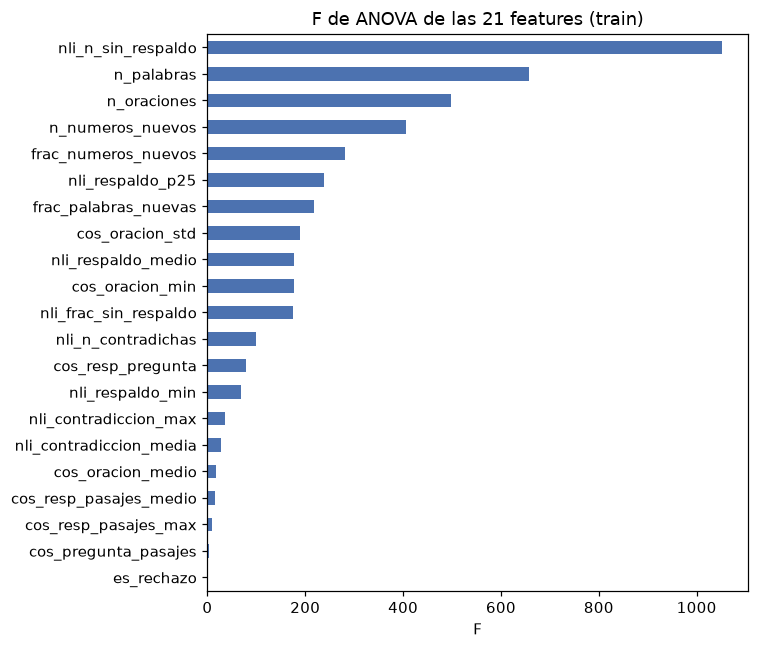

In [13]:
F, _ = f_classif(X_train, y_train)
ranking = pd.Series(F, index=COLS).sort_values()

ranking.plot.barh(figsize=(7, 6), color="#4C72B0")
plt.title("F de ANOVA de las 21 features (train)")
plt.xlabel("F")
plt.tight_layout()
plt.show()

### Líneas base

Antes de optimizar necesito saber cuál es el mínimo a superar:

- **Siempre "alucinada":** un modelo que marca todo como alucinación.
- **Solo similitud:** regresión logística con una sola feature (la similitud coseno entre la respuesta y los pasajes). Es la idea más simple que se me ocurre para medir respaldo.
- **Los dos pipelines con valores por defecto**, sin optimizar.

In [14]:
i_cos = COLS.index("cos_resp_pasajes_max")
base = {
    "Siempre 'alucinada'": evaluar(DummyClassifier(strategy="constant", constant=1), cv_opt),
    "Solo similitud coseno": evaluar(Pipeline([("escala", StandardScaler()),
                                               ("clf", LogisticRegression(class_weight="balanced"))]),
                                     cv_opt, X=X_train[:, [i_cos]]),
    "Logística por defecto": evaluar(pipe_lr(), cv_opt),
    "XGBoost por defecto": evaluar(pipe_xgb(), cv_opt),
}
tabla_base = pd.DataFrame({n: [s.mean(), s.std()] for n, s in base.items()}, index=["F1 medio", "desv."]).T.round(3)
tabla_base

,F1 medio,desv.
Siempre 'alucinada',0.474,0.002
Solo similitud coseno,0.382,0.018
Logística por defecto,0.628,0.013
XGBoost por defecto,0.593,0.018


### ¿Qué grupo de features aporta?

Antes de optimizar reviso cuánto aporta cada grupo de features por separado, con los dos modelos por defecto y sin selección. Así sé si las features de transfer learning (NLI, similitud y embedding) suman algo sobre las features simples.

In [15]:
grupos = {
    "Solo simples": COLS_SIMPLES,
    "Solo similitud": COLS_SIM,
    "Solo NLI": COLS_NLI,
    "Solo embedding": COLS_EMB,
    "Simples + similitud": COLS_SIMPLES + COLS_SIM,
    "Simples + NLI": COLS_SIMPLES + COLS_NLI,
    "Respaldo (simples + similitud + NLI)": COLS_RESPALDO,
    "Respaldo + embedding": COLS_RESPALDO + COLS_EMB,
}
filas = {}
for nombre, cols in grupos.items():
    X_grupo = feats.loc[es_train, cols].values
    f1_l = evaluar(pipe_lr(), cv_opt, X=X_grupo)
    f1_x = evaluar(pipe_xgb(), cv_opt, X=X_grupo)
    filas[nombre] = {"n_features": len(cols), "Logística F1": f1_l.mean(), "XGBoost F1": f1_x.mean()}
pd.DataFrame(filas).T.astype({"n_features": int}).round(3)

,n_features,Logística F1,XGBoost F1
Solo simples,6,0.618,0.587
Solo similitud,7,0.516,0.478
Solo NLI,8,0.590,0.528
Solo embedding,384,0.478,0.377
Simples + similitud,13,0.621,0.576
Simples + NLI,14,0.631,0.595
Respaldo (simples + similitud + NLI),21,0.628,0.593
Respaldo + embedding,405,0.570,0.592


**Lo que veo en las líneas base y los grupos de features**

- El mínimo a superar es **F1 = 0,474** (marcar todo como alucinación).
- **La similitud coseno sola no sirve:** saca 0,382, peor que el mínimo. Que una respuesta se parezca a los pasajes no quiere decir que esté respaldada por ellos.
- **Las features simples ya logran casi todo:** con solo 6 features (largo, números y palabras nuevas) la logística llega a 0,618.
- **El NLI aporta, pero poco:** solo llega a 0,590, y sumado a las simples sube el F1 a 0,631 (+0,013).
- **El embedding de la respuesta no sirve para esta tarea:** solo saca 0,478, igual que el mínimo, y si lo sumo a las 21 features de respaldo la logística baja de 0,628 a 0,570. Esto confirma la decisión de no usarlo como entrada del modelo.
- En el ranking de ANOVA la feature más fuerte es `nli_n_sin_respaldo` (cuántas oraciones no tienen respaldo), seguida del largo de la respuesta (`n_palabras`, `n_oraciones`) y de los números que no aparecen en los pasajes. `es_rechazo` y `cos_pregunta_pasajes` casi no separan las clases por sí solas.

## 8. Optimización de hiperparámetros

Uso **Optuna** [10]: en vez de probar todas las combinaciones de una grilla, va proponiendo combinaciones nuevas según lo que le fue bien en las anteriores.

Cada combinación se evalúa con **repeated k-fold** agrupado (3 repeticiones × 5 folds = 15 evaluaciones) y Optuna maximiza el F1 promedio. Todo esto ocurre solo con el train.

| Modelo | Hiperparámetros |
|---|---|
| Logística | `k` (features seleccionadas), `C` (inverso de la regularización) |
| XGBoost | `k`, `n_estimators`, `max_depth`, `learning_rate`, `subsample`, `colsample_bytree` |

In [16]:
N_TRIALS = 40


def objetivo_lr(trial):
    pipe = pipe_lr(k=trial.suggest_int("k", 3, len(COLS)),
                   C=trial.suggest_float("C", 1e-4, 10, log=True))
    return evaluar(pipe, cv_opt).mean()


def objetivo_xgb(trial):
    pipe = pipe_xgb(k=trial.suggest_int("k", 3, len(COLS)),
                    n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
                    max_depth=trial.suggest_int("max_depth", 2, 6),
                    learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
                    subsample=trial.suggest_float("subsample", 0.6, 1.0),
                    colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0))
    return evaluar(pipe, cv_opt).mean()


estudio_lr = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio_lr.optimize(objetivo_lr, n_trials=N_TRIALS)
estudio_xgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio_xgb.optimize(objetivo_xgb, n_trials=N_TRIALS)

print("Logística:", estudio_lr.best_params, "-> F1 CV =", round(estudio_lr.best_value, 4))
print("XGBoost:  ", estudio_xgb.best_params, "-> F1 CV =", round(estudio_xgb.best_value, 4))

mejor_lr = pipe_lr(**estudio_lr.best_params)
mejor_xgb = pipe_xgb(**estudio_xgb.best_params)

Logística: {'k': 21, 'C': 0.2323807552058671} -> F1 CV = 0.6289
XGBoost:   {'k': 16, 'n_estimators': 350, 'max_depth': 4, 'learning_rate': 0.015645485352724354, 'subsample': 0.8802756287434637, 'colsample_bytree': 0.6648332192967724} -> F1 CV = 0.6422


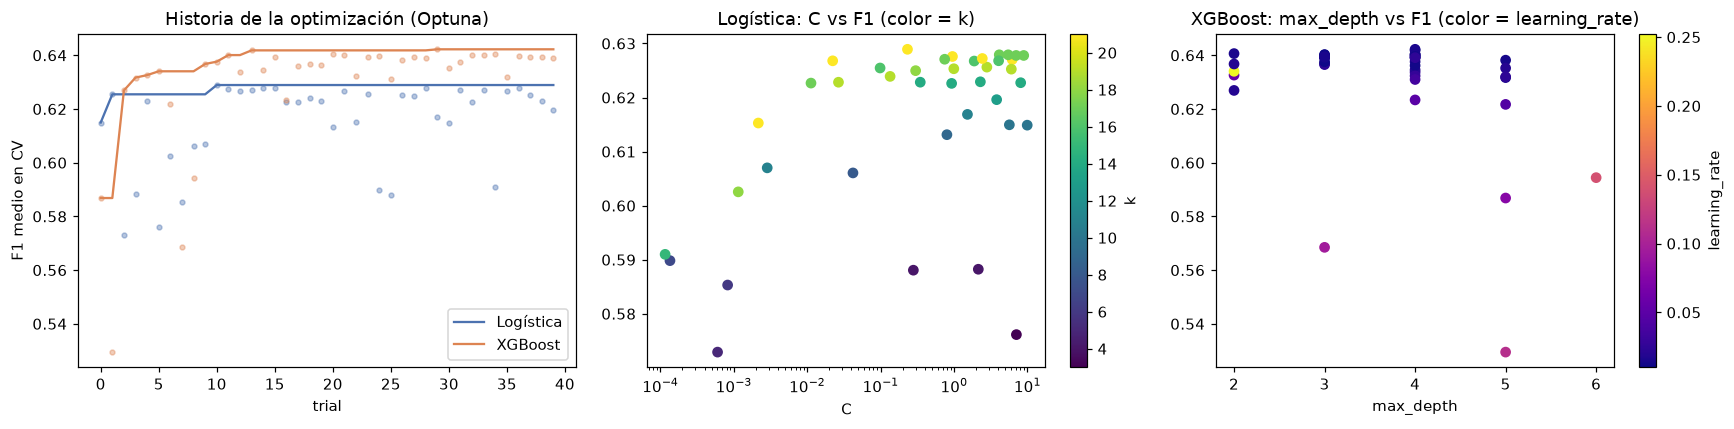

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

for estudio, nombre, color in [(estudio_lr, "Logística", "#4C72B0"), (estudio_xgb, "XGBoost", "#DD8452")]:
    valores = [t.value for t in estudio.trials]
    ax[0].plot(np.maximum.accumulate(valores), color=color, label=nombre)
    ax[0].scatter(range(len(valores)), valores, color=color, s=10, alpha=0.4)
ax[0].set_title("Historia de la optimización (Optuna)")
ax[0].set_xlabel("trial")
ax[0].set_ylabel("F1 medio en CV")
ax[0].legend()

t_lr = estudio_lr.trials_dataframe()
sc = ax[1].scatter(t_lr["params_C"], t_lr["value"], c=t_lr["params_k"], cmap="viridis")
ax[1].set_xscale("log")
ax[1].set_title("Logística: C vs F1 (color = k)")
ax[1].set_xlabel("C")
plt.colorbar(sc, ax=ax[1], label="k")

t_xgb = estudio_xgb.trials_dataframe()
sc = ax[2].scatter(t_xgb["params_max_depth"], t_xgb["value"], c=t_xgb["params_learning_rate"], cmap="plasma")
ax[2].set_title("XGBoost: max_depth vs F1 (color = learning_rate)")
ax[2].set_xlabel("max_depth")
plt.colorbar(sc, ax=ax[2], label="learning_rate")
plt.tight_layout()
plt.show()

### Gráfica de un hiperparámetro: `C` de la regresión logística

Dejo fijo el `k` que encontró Optuna y muevo solo `C`. Con `C` pequeño la regularización es fuerte (modelo más simple) y con `C` grande es débil (modelo más libre).

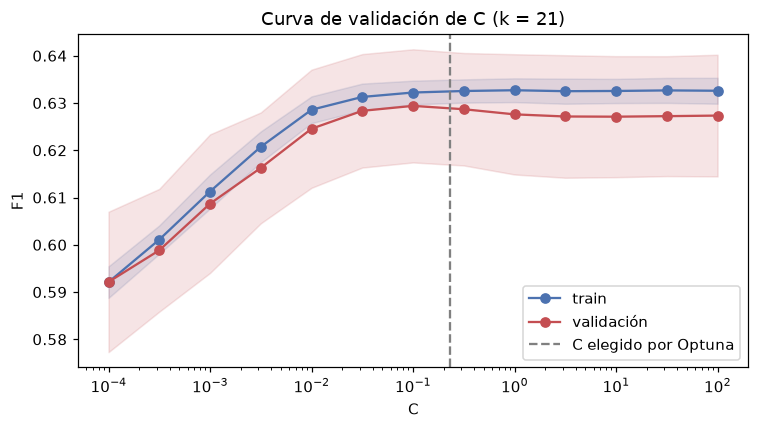

In [18]:
rango_C = np.logspace(-4, 2, 13)
f1_tr, f1_va = validation_curve(mejor_lr, X_train, y_train, param_name="clf__C", param_range=rango_C,
                                cv=cv_opt, scoring="f1", n_jobs=-1)

plt.figure(figsize=(7, 4))
for datos, nombre, color in [(f1_tr, "train", "#4C72B0"), (f1_va, "validación", "#C44E52")]:
    plt.plot(rango_C, datos.mean(axis=1), "o-", color=color, label=nombre)
    plt.fill_between(rango_C, datos.mean(axis=1) - datos.std(axis=1), datos.mean(axis=1) + datos.std(axis=1),
                     color=color, alpha=0.15)
plt.axvline(estudio_lr.best_params["C"], color="gray", ls="--", label="C elegido por Optuna")
plt.xscale("log")
plt.xlabel("C")
plt.ylabel("F1")
plt.title(f"Curva de validación de C (k = {estudio_lr.best_params['k']})")
plt.legend()
plt.tight_layout()
plt.show()

### Curva de validación de `k` (selección de features)

Para ver qué hace la selección de features, dejo fijo el `C` que encontró Optuna y muevo solo `k`, el número de features que deja `SelectKBest`.

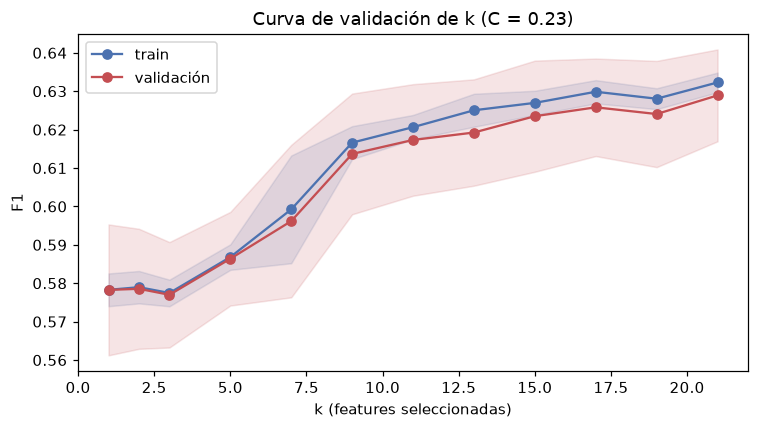

In [19]:
rango_k = [1, 2, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
f1_tr, f1_va = validation_curve(mejor_lr, X_train, y_train, param_name="sel__k", param_range=rango_k,
                                cv=cv_opt, scoring="f1", n_jobs=-1)

plt.figure(figsize=(7, 4))
for datos, nombre, color in [(f1_tr, "train", "#4C72B0"), (f1_va, "validación", "#C44E52")]:
    plt.plot(rango_k, datos.mean(axis=1), "o-", color=color, label=nombre)
    plt.fill_between(rango_k, datos.mean(axis=1) - datos.std(axis=1), datos.mean(axis=1) + datos.std(axis=1),
                     color=color, alpha=0.15)
plt.xlabel("k (features seleccionadas)")
plt.ylabel("F1")
plt.title(f"Curva de validación de k (C = {estudio_lr.best_params['C']:.2f})")
plt.legend()
plt.tight_layout()
plt.show()

### Curva de aprendizaje

Muestra cómo cambia el F1 de train y de validación al entrenar con más datos. Sirve para diagnosticar si el modelo tiene sesgo alto (las dos curvas bajas y juntas) o varianza alta (mucha distancia entre las dos).

Marco dos referencias:
- **Desempeño deseado: F1 = 0,68**, que es lo que logra en QA el mejor detector del paper de RAGTruth (un Llama-2-13B con fine-tuning) [2].
- **Mínimo:** el F1 de marcar todo como alucinación.

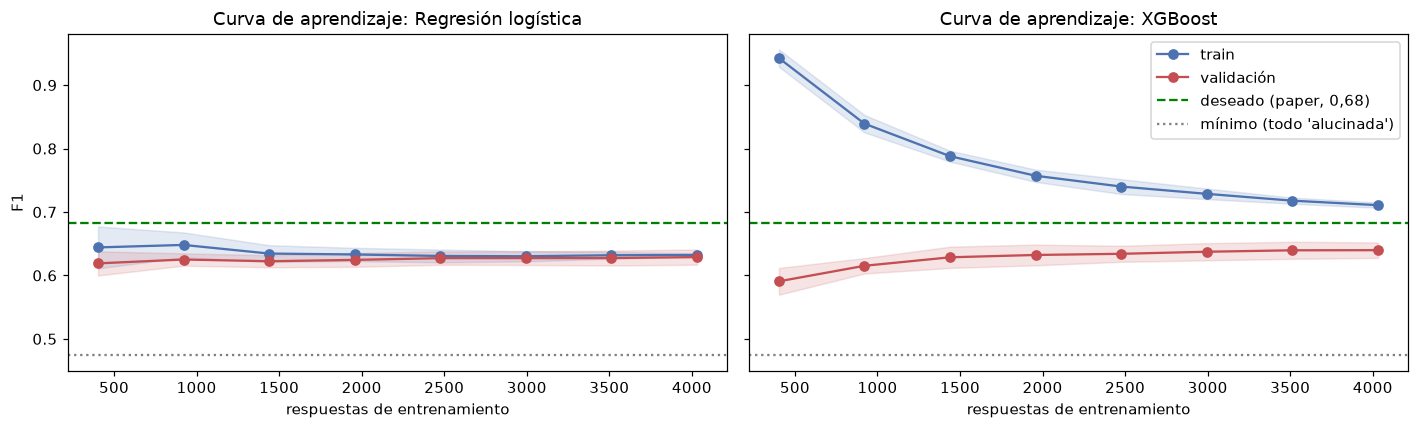

In [20]:
F1_DESEADO = 0.682
f1_minimo = base["Siempre 'alucinada'"].mean()
tamanos = np.linspace(0.1, 1.0, 8)

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, pipe, nombre in [(ax[0], mejor_lr, "Regresión logística"), (ax[1], mejor_xgb, "XGBoost")]:
    n, f1_tr, f1_va = learning_curve(pipe, X_train, y_train, train_sizes=tamanos, cv=cv_opt, scoring="f1",
                                     shuffle=True, random_state=SEMILLA, n_jobs=-1)
    for datos, etiqueta, color in [(f1_tr, "train", "#4C72B0"), (f1_va, "validación", "#C44E52")]:
        a.plot(n, datos.mean(axis=1), "o-", color=color, label=etiqueta)
        a.fill_between(n, datos.mean(axis=1) - datos.std(axis=1), datos.mean(axis=1) + datos.std(axis=1),
                       color=color, alpha=0.15)
    a.axhline(F1_DESEADO, color="green", ls="--", label="deseado (paper, 0,68)")
    a.axhline(f1_minimo, color="gray", ls=":", label="mínimo (todo 'alucinada')")
    a.set_title("Curva de aprendizaje: " + nombre)
    a.set_xlabel("respuestas de entrenamiento")
ax[0].set_ylabel("F1")
ax[1].legend()
plt.tight_layout()
plt.show()

**Lo que veo en la optimización**

- **Mejores hiperparámetros:**
  - Logística: `k = 21`, `C = 0,23` → F1 = 0,629.
  - XGBoost: `k = 16`, 350 árboles, `max_depth = 4`, `learning_rate = 0,016` → F1 = 0,642.
- **A XGBoost la optimización le sirvió mucho** (pasó de 0,593 por defecto a 0,642). A la logística casi nada (de 0,628 a 0,629).
- **Selección de features:** la logística se quedó con las 21. XGBoost se quedó con 16 y dejó fuera las 5 con menor F de ANOVA (`es_rechazo`, `cos_pregunta_pasajes`, `cos_resp_pasajes_max`, `cos_resp_pasajes_medio` y `cos_oracion_medio`), que casi no separan las clases.
- **Curva de validación de `C`:** con `C` menor a 0,01 el modelo queda demasiado regularizado y el F1 baja a 0,59 (underfitting). Desde `C = 0,03` la curva es plana, y train (0,633) y validación (0,628) están casi juntas, así que no hay overfitting.
- **Curva de validación de `k`:** con 1 a 3 features el F1 se queda en 0,58 y sube a medida que entran más, hasta 0,629 con las 21. Train y validación van juntas en toda la curva: en la logística más features no producen overfitting.
- **Curva de aprendizaje de la logística:** train y validación se juntan en 0,63 desde las 1 500 respuestas, por debajo del deseado (0,68). Es **sesgo alto**: más datos no van a ayudar, lo que falta es mejor información en las features.
- **Curva de aprendizaje de XGBoost:** train baja de 0,94 a 0,71 y validación sube de 0,59 a 0,64. Todavía queda una distancia de 0,07 (algo de varianza), y la validación sube muy poco desde las 2 500 respuestas.
- Los dos modelos superan con claridad el mínimo (0,474) y ninguno alcanza el deseado (0,68).

## 9. Comparación estadística de las dos técnicas

Ya con los dos modelos optimizados, los evalúo con **10 repeticiones × 10 folds** (100 valores de F1 por modelo). Los dos usan exactamente **las mismas particiones**, así que los resultados son pareados: el valor 37 de la logística y el valor 37 de XGBoost salen del mismo fold.

Para saber si la diferencia es real o podría ser casualidad uso el **test de Wilcoxon** para muestras pareadas [11], [12]:

- **H₀:** no hay diferencia entre los dos modelos.
- Si **p < 0,05**, rechazo H₀ y digo que la diferencia es significativa.

Uso Wilcoxon en vez del t-test pareado porque no asume que las diferencias sigan una distribución normal.

Logística: F1 = 0.6274 ± 0.0259
XGBoost:   F1 = 0.6407 ± 0.0267
Diferencia media (XGBoost - Logística): +0.0133
XGBoost gana en 77 de 100 folds
Wilcoxon: estadístico = 637.0, p = 8.50e-11


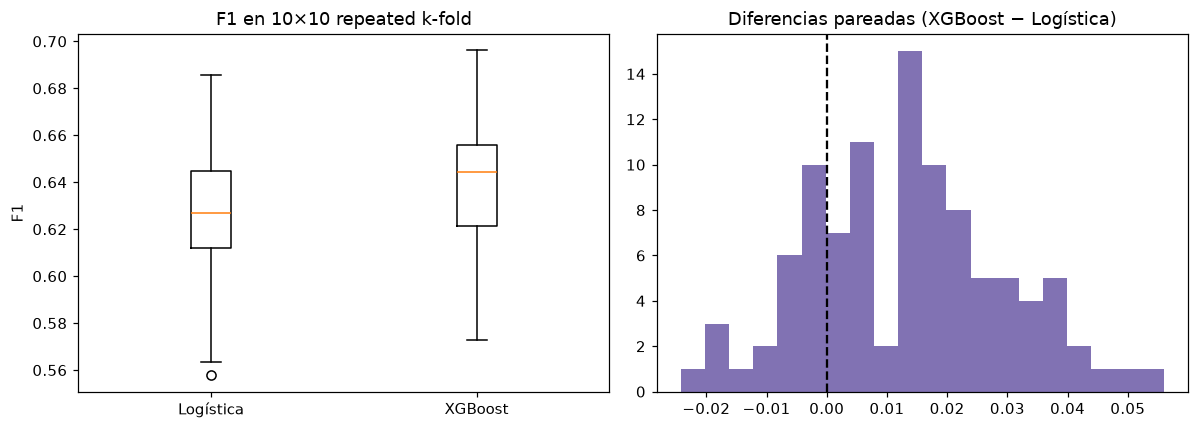

In [21]:
f1_lr = evaluar(mejor_lr, cv_comp)
f1_xgb = evaluar(mejor_xgb, cv_comp)
estadistico, p_valor = wilcoxon(f1_lr, f1_xgb)

print(f"Logística: F1 = {f1_lr.mean():.4f} ± {f1_lr.std():.4f}")
print(f"XGBoost:   F1 = {f1_xgb.mean():.4f} ± {f1_xgb.std():.4f}")
print(f"Diferencia media (XGBoost - Logística): {(f1_xgb - f1_lr).mean():+.4f}")
print(f"XGBoost gana en {(f1_xgb > f1_lr).sum()} de {len(f1_lr)} folds")
print(f"Wilcoxon: estadístico = {estadistico:.1f}, p = {p_valor:.2e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].boxplot([f1_lr, f1_xgb])
ax[0].set_xticklabels(["Logística", "XGBoost"])
ax[0].set_title("F1 en 10×10 repeated k-fold")
ax[0].set_ylabel("F1")
ax[1].hist(f1_xgb - f1_lr, bins=20, color="#8172B3")
ax[1].axvline(0, color="black", ls="--")
ax[1].set_title("Diferencias pareadas (XGBoost − Logística)")
plt.tight_layout()
plt.show()

In [22]:
# Si la diferencia es significativa me quedo con el de mayor F1; si no, con el más simple (logística).
if p_valor < 0.05 and f1_xgb.mean() > f1_lr.mean():
    nombre_final, modelo_final = "XGBoost", mejor_xgb
else:
    nombre_final, modelo_final = "Regresión logística", mejor_lr
print("Modelo elegido:", nombre_final)

Modelo elegido: XGBoost


**Lo que veo en la comparación**

- Logística: F1 = 0,627 ± 0,026. XGBoost: F1 = 0,641 ± 0,027.
- XGBoost gana en 77 de los 100 folds, con una diferencia media de +0,013.
- **Wilcoxon: p = 8,5 × 10⁻¹¹.** Como es mucho menor que 0,05, rechazo H₀: la diferencia a favor de XGBoost es estadísticamente significativa.
- La diferencia es pequeña (poco más de un punto de F1), pero es consistente: XGBoost gana en casi 8 de cada 10 folds. Tiene sentido, porque los árboles pueden combinar features de forma no lineal (por ejemplo, una respuesta larga *y* con oraciones sin respaldo).
- Me quedo con XGBoost, que es la regla que fijé antes de ver el resultado.

## 10. Visualización con t-SNE

t-SNE [13] comprime muchas dimensiones a 2 para poder graficar, tratando de que los puntos que estaban cerca sigan cerca. Solo sirve para **mirar** los datos: no entrena ni evalúa nada.

El t-SNE importante es el de **lo que ve el modelo**: la salida del pipeline final justo antes del clasificador (las `k` features que dejó `SelectKBest`). Grafico una muestra de 3 000 respuestas de train:

1. Entrada del modelo final, coloreada por la etiqueta.
2. Entrada del modelo final, coloreada por el LLM que escribió la respuesta.
3. Para comparar, el embedding de la respuesta (384 dimensiones), que no entra al modelo.

Para el gráfico escalo las features, porque t-SNE trabaja con distancias y sin escalar dominaría la feature con números más grandes (el largo de la respuesta).

Features que ve el modelo: [np.str_('nli_respaldo_min'), np.str_('nli_respaldo_medio'), np.str_('nli_respaldo_p25'), np.str_('nli_n_sin_respaldo'), np.str_('nli_frac_sin_respaldo'), np.str_('nli_contradiccion_max'), np.str_('nli_contradiccion_media'), np.str_('nli_n_contradichas'), np.str_('cos_resp_pregunta'), np.str_('cos_oracion_min'), np.str_('cos_oracion_std'), np.str_('n_palabras'), np.str_('n_oraciones'), np.str_('frac_palabras_nuevas'), np.str_('n_numeros_nuevos'), np.str_('frac_numeros_nuevos')]


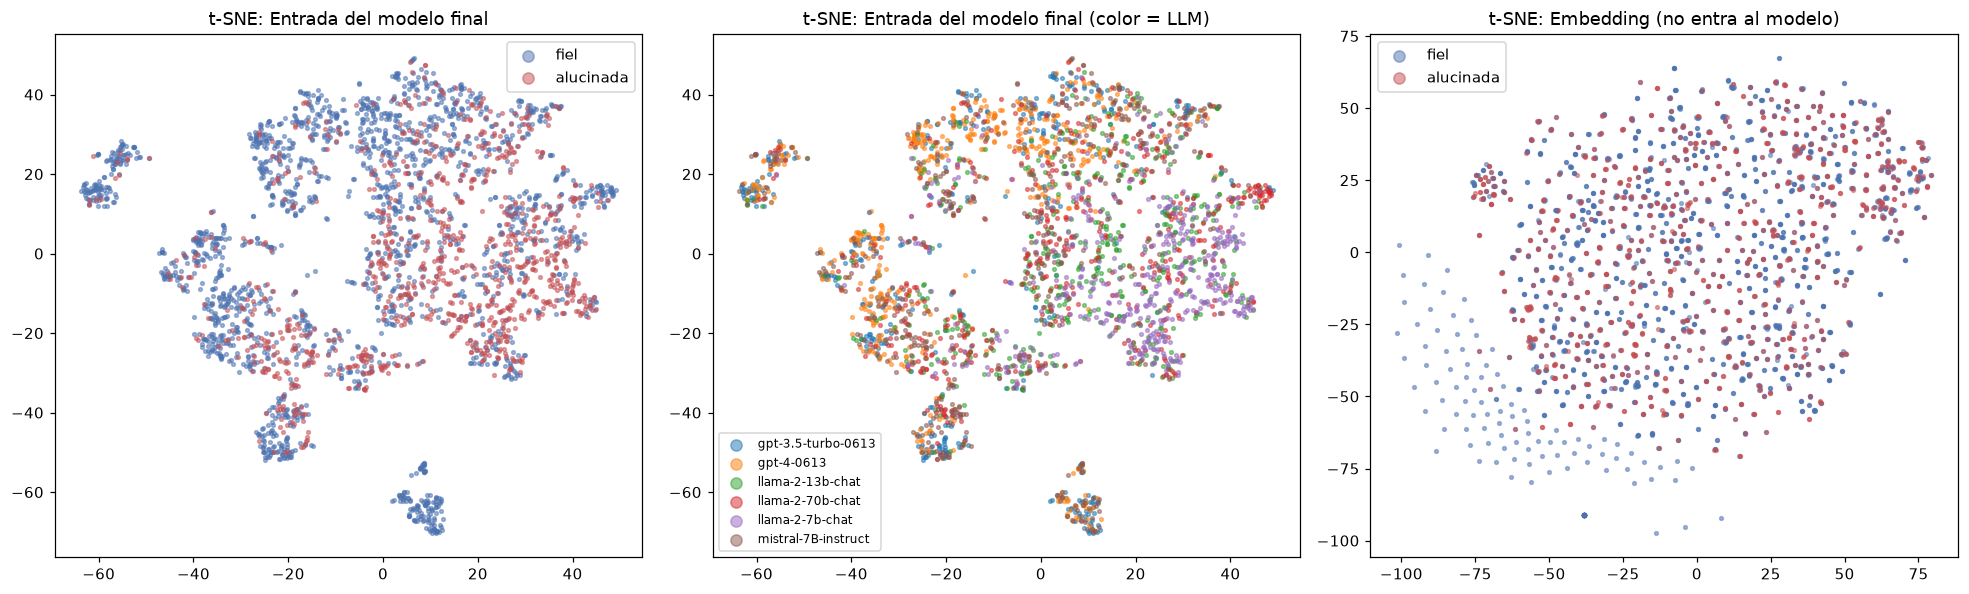

In [23]:
rng = np.random.RandomState(SEMILLA)
muestra = rng.choice(np.where(es_train)[0], size=3000, replace=False)
y_m = df.loc[muestra, "y"].values
llm_m = df.loc[muestra, "llm"].values

modelo_final.fit(X_train, y_train)
entrada = modelo_final[:-1].transform(feats.loc[muestra, COLS].values)
print("Features que ve el modelo:", list(np.array(COLS)[modelo_final.named_steps["sel"].get_support()]))

tsne_modelo = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEMILLA).fit_transform(
    StandardScaler().fit_transform(entrada))
tsne_emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEMILLA).fit_transform(
    feats.loc[muestra, COLS_EMB].values)

fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))
for a, Z, titulo in [(ax[0], tsne_modelo, "Entrada del modelo final"), (ax[2], tsne_emb, "Embedding (no entra al modelo)")]:
    for clase, color, nombre in [(0, "#4C72B0", "fiel"), (1, "#C44E52", "alucinada")]:
        a.scatter(Z[y_m == clase, 0], Z[y_m == clase, 1], s=6, alpha=0.5, color=color, label=nombre)
    a.set_title("t-SNE: " + titulo)
    a.legend(markerscale=3)
for llm in sorted(set(llm_m)):
    ax[1].scatter(tsne_modelo[llm_m == llm, 0], tsne_modelo[llm_m == llm, 1], s=6, alpha=0.5, label=llm)
ax[1].set_title("t-SNE: Entrada del modelo final (color = LLM)")
ax[1].legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

**Lo que veo en el t-SNE**

- **Entrada del modelo final (las 16 features que deja `SelectKBest`):** a la izquierda y arriba dominan las respuestas fieles, y a la derecha se concentran las alucinadas. Pero en el centro las dos clases están muy superpuestas: no existe una separación limpia, y eso explica por qué ningún modelo pasa de 0,64.
- **Coloreado por LLM:** GPT-4 y GPT-3.5 quedan sobre todo en la zona de las fieles, y Llama-2-7B y Llama-2-70B en la zona de las alucinadas, aunque nunca le di al modelo qué LLM escribió cada respuesta. Las features capturan en parte el "estilo" de cada LLM, así que el verificador podría rendir distinto con un LLM que no esté en este corpus.
- **Embedding de la respuesta:** las fieles y las alucinadas salen completamente mezcladas. El embedding captura de qué habla la respuesta, no si está respaldada, y por eso no lo uso como entrada del modelo.

## 11. Evaluación final en test

Hasta aquí no toqué el test. Ahora:

1. **Elijo el umbral** con el train: saco predicciones *out-of-fold* (cada respuesta la predice un modelo que no la vio) y busco el umbral que maximiza F1. No uso el test para elegirlo.
2. **Reentreno** el modelo elegido con todo el train.
3. **Evalúo una sola vez** en el test.

Hay que tener en cuenta que el test tiene menos alucinaciones (17,8 %) que el train (31,1 %), así que es un escenario un poco distinto.

In [24]:
cv_umbral = list(StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEMILLA).split(X_train, y_train, g_train))
proba_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv_umbral, method="predict_proba", n_jobs=-1)[:, 1]

prec, rec, umbrales = precision_recall_curve(y_train, proba_oof)
f1_umbral = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
UMBRAL = float(umbrales[f1_umbral.argmax()])
print(f"Umbral elegido con train (out-of-fold): {UMBRAL:.3f} | F1 out-of-fold = {f1_umbral.max():.3f}")

modelo_final.fit(X_train, y_train)
proba_test = modelo_final.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= UMBRAL).astype(int)

Umbral elegido con train (out-of-fold): 0.537 | F1 out-of-fold = 0.641


In [25]:
resultados = pd.DataFrame({
    "precision": [precision_score(y_test, pred_test), 0.616, 0.332, y_test.mean()],
    "recall": [recall_score(y_test, pred_test), 0.763, 0.906, 1.0],
    "F1": [f1_score(y_test, pred_test), 0.682, 0.456, f1_score(y_test, np.ones_like(y_test))],
}, index=[f"Este proyecto ({nombre_final})", "Paper: Llama-2-13B con fine-tuning [2]",
          "Paper: prompt a GPT-4-turbo [2]", "Marcar todo como 'alucinada'"]).round(3)
print(f"PR-AUC en test: {average_precision_score(y_test, proba_test):.3f} (al azar sería {y_test.mean():.3f})")
print(f"ROC-AUC en test: {roc_auc_score(y_test, proba_test):.3f}")
resultados

PR-AUC en test: 0.510 (al azar sería 0.178)
ROC-AUC en test: 0.811


,precision,recall,F1
Este proyecto (XGBoost),0.376,0.694,0.488
Paper: Llama-2-13B con fine-tuning [2],0.616,0.763,0.682
Paper: prompt a GPT-4-turbo [2],0.332,0.906,0.456
Marcar todo como 'alucinada',0.178,1.000,0.302


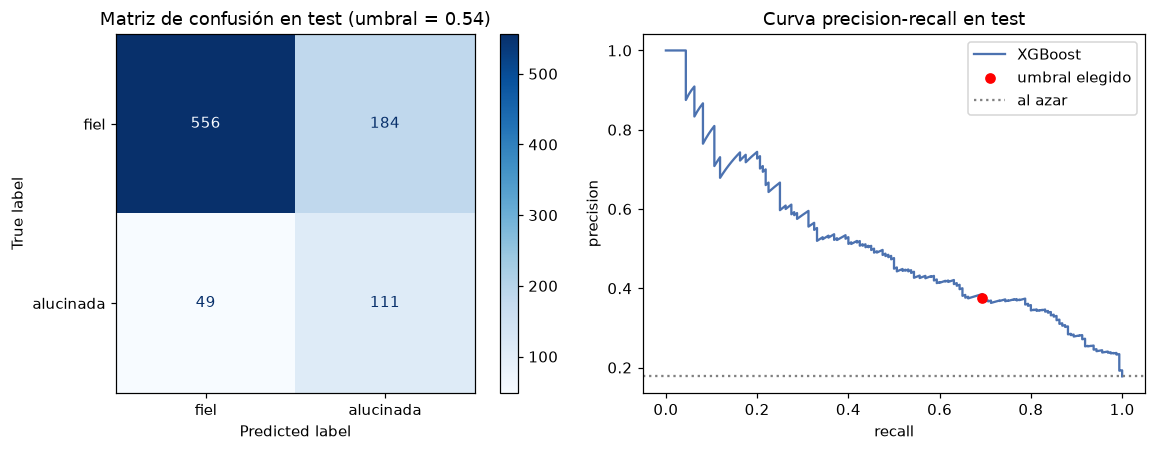

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["fiel", "alucinada"], cmap="Blues", ax=ax[0])
ax[0].set_title(f"Matriz de confusión en test (umbral = {UMBRAL:.2f})")

p_t, r_t, _ = precision_recall_curve(y_test, proba_test)
ax[1].plot(r_t, p_t, color="#4C72B0", label=nombre_final)
ax[1].scatter(recall_score(y_test, pred_test), precision_score(y_test, pred_test), color="red", zorder=3, label="umbral elegido")
ax[1].axhline(y_test.mean(), color="gray", ls=":", label="al azar")
ax[1].set_xlabel("recall")
ax[1].set_ylabel("precision")
ax[1].set_title("Curva precision-recall en test")
ax[1].legend()
plt.tight_layout()
plt.show()

In [27]:
df_test = df[~es_train].assign(pred=pred_test)
por_llm = df_test.groupby("llm").apply(lambda g: pd.Series({
    "respuestas": len(g), "alucinadas": int(g.y.sum()),
    "recall": recall_score(g.y, g.pred, zero_division=0), "precision": precision_score(g.y, g.pred, zero_division=0)}))
por_llm.round(3)

,respuestas,alucinadas,recall,precision
llm,,,,
gpt-3.5-turbo-0613,150.0,5.0,0.400,0.182
gpt-4-0613,150.0,1.0,0.000,0.000
llama-2-13b-chat,150.0,36.0,0.806,0.354
llama-2-70b-chat,150.0,35.0,0.629,0.415
llama-2-7b-chat,150.0,52.0,0.827,0.384
mistral-7B-instruct,150.0,31.0,0.484,0.469


**Lo que veo en el test**

- El umbral elegido con el train fue 0,537.
- **Resultado en test: precision 0,376, recall 0,694 y F1 0,488.** PR-AUC = 0,510 (al azar sería 0,178) y ROC-AUC = 0,811.
- **Matriz de confusión:** de las 160 respuestas alucinadas detecta 111 y se le escapan 49. De las 740 fieles marca 184 como alucinadas por error.
- **Comparación:**
  - Supera a marcar todo como alucinación (0,302).
  - Supera al prompt a GPT-4-turbo del paper (0,456).
  - No alcanza al Llama-2-13B con fine-tuning del paper (0,682).
- **El F1 baja de 0,64 en cross-validation a 0,49 en test.** La razón principal es que el test tiene menos alucinaciones (17,8 % contra 31,1 %): con menos positivos, los falsos positivos pesan más y la precision cae.
- **Por LLM:** detecta mejor las alucinaciones de Llama-2-7B y 13B (recall de 0,83 y 0,81) que las de Llama-2-70B (0,63) y Mistral (0,48). GPT-4 y GPT-3.5 solo tienen 1 y 5 alucinaciones en el test, así que de ellos no puedo concluir nada.

## 12. Conclusiones

1. **Se puede detectar una parte de las alucinaciones con un clasificador barato.** El modelo final (XGBoost) logra F1 = 0,64 en cross-validation, contra 0,47 de marcar todo como alucinación. En test logra 0,49, por encima del prompt a GPT-4-turbo del paper (0,456) y por debajo del modelo con fine-tuning (0,682).
2. **Lo que más ayuda a detectar una alucinación es contar cuántas oraciones no tienen respaldo según el NLI y qué tan larga es la respuesta.** Las respuestas largas y con números que no aparecen en los pasajes alucinan más.
3. **El transfer learning sin reentrenar aportó menos de lo que esperaba.** Las 6 features simples solas logran 0,618 y el NLI agrega 0,013. La similitud coseno sola (0,382) y el embedding de la respuesta (0,478) no sirven: parecerse a la fuente no es lo mismo que estar respaldado por ella.
4. **XGBoost fue significativamente mejor que la regresión logística (Wilcoxon, p = 8,5 × 10⁻¹¹), por 0,013 de F1.** La diferencia es pequeña pero consistente (gana en 77 de 100 folds).
5. **El límite está en las features, no en los datos ni en los hiperparámetros.** La curva de aprendizaje de la logística es plana en 0,63, las curvas de validación de `C` y de `k` también se aplanan, y la de XGBoost casi no sube con más datos. Para acercarse a 0,68 hace falta mejor información; por ejemplo, reentrenar (fine-tuning) el modelo NLI con este tipo de datos, que es lo que hace el paper.
6. **Limitaciones:**
   - Con precision de 0,38 en test, casi 2 de cada 3 alertas son falsas. Sirve como filtro para mandar respuestas a revisión, no como juez final.
   - El test tiene una proporción de alucinaciones distinta a la del train, y el umbral se eligió con el train.
   - Usé un solo corpus, en inglés y con preguntas generales (MS MARCO). No sé cómo rinde en otro dominio, en español o con un LLM que no esté en el corpus.
7. **Trabajo futuro:** en mi tema de titulación quiero probar este verificador al final de un RAG sobre un dominio específico, con un conjunto de evaluación propio y en español, y compararlo con un modelo NLI reentrenado.

## 13. Referencias

[1] P. Lewis *et al.*, "Retrieval-augmented generation for knowledge-intensive NLP tasks," in *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 33, 2020, pp. 9459–9474.

[2] C. Niu *et al.*, "RAGTruth: A hallucination corpus for developing trustworthy retrieval-augmented language models," in *Proc. 62nd Annu. Meeting Assoc. Comput. Linguistics (ACL)*, 2024. Datos: https://github.com/ParticleMedia/RAGTruth

[3] P. Bajaj *et al.*, "MS MARCO: A human generated machine reading comprehension dataset," arXiv:1611.09268, 2016.

[4] N. Reimers and I. Gurevych, "Sentence-BERT: Sentence embeddings using Siamese BERT-networks," in *Proc. Conf. Empirical Methods in Natural Language Processing (EMNLP)*, 2019, pp. 3982–3992.

[5] W. Wang, F. Wei, L. Dong, H. Bao, N. Yang, and M. Zhou, "MiniLM: Deep self-attention distillation for task-agnostic compression of pre-trained transformers," in *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 33, 2020, pp. 5776–5788.

[6] P. He, J. Gao, and W. Chen, "DeBERTaV3: Improving DeBERTa using ELECTRA-style pre-training with gradient-disentangled embedding sharing," in *Proc. Int. Conf. Learning Representations (ICLR)*, 2023.

[7] P. Laban, T. Schnabel, P. N. Bennett, and M. A. Hearst, "SummaC: Re-visiting NLI-based models for inconsistency detection in summarization," *Trans. Assoc. Comput. Linguistics*, vol. 10, pp. 163–177, 2022.

[8] T. Chen and C. Guestrin, "XGBoost: A scalable tree boosting system," in *Proc. 22nd ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining*, 2016, pp. 785–794.

[9] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[10] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, "Optuna: A next-generation hyperparameter optimization framework," in *Proc. 25th ACM SIGKDD Int. Conf. Knowledge Discovery and Data Mining*, 2019, pp. 2623–2631.

[11] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, 1945.

[12] J. Demšar, "Statistical comparisons of classifiers over multiple data sets," *J. Mach. Learn. Res.*, vol. 7, pp. 1–30, 2006.

[13] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.